In [22]:
import json
import sys
from datetime import datetime
from pathlib import Path
from typing import List

import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
from src.analytics import VarianceCalculator
from src.core.schemas import OptionChain, TradeSignal, VolatilityMetrics
from src.portfolio.backtester import PortfolioSimulator

INITIAL_CAPITAL = 1_000_000.0
TRANSACTION_COST_BPS = 5.0
ANN_FACTOR = 252
TARGET_DAYS = 30

 ## Copie locale du signal

Copie de `SignalGenerator` pour pouvoir tester avant le merge. **À supprimer et remplacer par l'import une fois mergé.**

In [23]:
class SignalGenerator:
    """Copie locale du signal de Adam, à retirer une fois mergé."""

    def _derive_target_weight(self, svix_annualized: float) -> float:
        premium_bound = 0.5 * svix_annualized**2
        return min(1.0, premium_bound)

    def generate_signals(self, metrics_history: List[VolatilityMetrics]) -> List[TradeSignal]:
        df = pd.DataFrame([vars(metrics) for metrics in metrics_history])
        signals = []
        for _, row in df.iterrows():
            signal_date = row["date"]
            execution_date = (pd.Timestamp(signal_date) + pd.offsets.BDay(1)).to_pydatetime()
            signals.append(
                TradeSignal(
                    signal_date=signal_date,
                    target_execution_date=execution_date,
                    underlying_price_at_signal=row["underlying_price"],
                    target_weight=self._derive_target_weight(row["svix_annualized"]),
                    risk_free_rate=row["risk_free_rate"],
                    dividend_yield=row["dividend_yield"],
                )
            )
        return signals

## Helpers

- `D0` : date de départ (lundi).
- `bday` : ajoute des jours ouvrables.
- `make_signal` : signal émis au i-ème jour, exécuté le lendemain.
- `make_metrics` : `VolatilityMetrics` synthétique, sans passer par l'analytics.
- `new_sim` : simulateur avec les paramètres du backtest.
- `run_backtest` : signal → simulateur.

In [24]:
D0 = datetime(2026, 11, 2)  # lundi


def bday(d, n=0):
    return (pd.Timestamp(d) + pd.offsets.BDay(n)).to_pydatetime()


def make_signal(i, weight, price=100.0, rf=0.0, div=0.0):
    return TradeSignal(
        signal_date=bday(D0, i),
        target_execution_date=bday(D0, i + 1),
        underlying_price_at_signal=price,
        target_weight=weight,
        risk_free_rate=rf,
        dividend_yield=div,
    )


def make_metrics(date, s0, svix, r=0.0, q=0.0):
    return VolatilityMetrics(
        date=date,
        maturity_days=30.0,
        is_interpolated=True,
        underlying_price=s0,
        risk_free_rate=r,
        dividend_yield=q,
        svix_annualized=svix,
        vix_annualized=svix,
        min_strike_used=2000.0,
        max_strike_used=8000.0,
        integration_points=1201,
    )


def new_sim():
    return PortfolioSimulator(
        initial_capital=INITIAL_CAPITAL,
        transaction_cost_bps=TRANSACTION_COST_BPS,
        annualization_factor=ANN_FACTOR,
    )


def run_backtest(history):
    signals = SignalGenerator().generate_signals(history)
    sim = new_sim()
    ledger = sim.run_simulation(signals)
    return signals, ledger, sim.metrics

## Test de `calculate_transaction_costs`

Coût = |poids cible − poids actuel| × valeur du portefeuille × bps.

In [14]:
sim = new_sim()


assert abs(sim._calculate_transaction_costs(0.0, 0.02, 1e6) - 10.0) < 1e-9

assert abs(sim._calculate_transaction_costs(0.5, 0.3, 2e6) - 200.0) < 1e-9

assert sim._calculate_transaction_costs(0.1, 0.1, 1e6) == 0.0

assert sim._calculate_transaction_costs(0.3, 0.5, 2e6) == sim._calculate_transaction_costs(0.5, 0.3, 2e6)

assert PortfolioSimulator(transaction_cost_bps=0.0)._calculate_transaction_costs(0.0, 1.0, 1e6) == 0.0

print("OK calculate_transaction_costs")

OK calculate_transaction_costs


## Test de `compute_risk_metrics`

- Max drawdown calculé à la main.
- Sharpe, Sortino et Calmar recalculés indépendamment.
- Cas limites : ruine, courbe plate, historique trop court.

In [15]:
sim = new_sim()

# Max drawdown manuel : pic 120, creux 90 -> -25 %
m = sim._compute_risk_metrics(pd.Series([100.0, 120.0, 90.0, 110.0]), risk_free=0.0)
assert abs(m["Max_Drawdown"] - (-0.25)) < 1e-12

# Recalcul indépendant de tous les ratios
eq = pd.Series([100.0, 102.0, 101.0, 105.0, 107.0, 104.0])
rf = 0.02
m = sim._compute_risk_metrics(eq, risk_free=rf)

r = eq.pct_change().dropna()
ex = r - rf / 252
sharpe_ref = ex.mean() / ex.std() * np.sqrt(252)
downside_ref = np.sqrt((ex.clip(upper=0) ** 2).mean())
sortino_ref = ex.mean() / downside_ref * np.sqrt(252)
years = len(r) / 252
ann_ref = (eq.iloc[-1] / eq.iloc[0]) ** (1 / years) - 1
mdd_ref = (eq / eq.cummax() - 1).min()
calmar_ref = ann_ref / abs(mdd_ref)

for key, ref in [("Sharpe", sharpe_ref), ("Sortino", sortino_ref), ("Calmar", calmar_ref), ("Max_Drawdown", mdd_ref)]:
    assert abs(m[key] - ref) < 1e-9, (key, m[key], ref)

# Cas limites
m = sim._compute_risk_metrics(pd.Series([100.0, 50.0, -10.0]))  # ruine
assert np.isnan(m["Sharpe"]) and m["Max_Drawdown"] == -1.0

m = sim._compute_risk_metrics(pd.Series([100.0] * 5))  # écart-type nul
assert np.isnan(m["Sharpe"]) and np.isnan(m["Max_Drawdown"])

m = sim._compute_risk_metrics(pd.Series([100.0, 101.0]))  # trop peu de points
assert np.isnan(m["Sharpe"])

# Un taux sans risque plus élevé réduit le Sharpe
assert sim._compute_risk_metrics(eq, 0.0)["Sharpe"] > sim._compute_risk_metrics(eq, 0.05)["Sharpe"]

print("OK compute_risk_metrics")

OK compute_risk_metrics


## Test de `run_simulation`

- A : premier rebalancement avec coût
- B : intérêts sur la trésorerie
- C : dividende sur position pleine
- D : poids réalisé égal au poids cible
- E : indépendance à l'ordre d'entrée
- F : cohérence du rendement quotidien
- G : rejet des prix invalides
- H : métriques stockées dans l'instance
- I : liste vide (**échec connu**, bug du module)

In [16]:
# A. Premier rebalancement : poids 50 %, coût 250 $
led = new_sim().run_simulation([make_signal(0, 0.5)])
row = led.iloc[0]
assert abs(row["Total_Equity"] - 999_750.0) < 1e-6
assert abs(row["Cash"] - 499_875.0) < 1e-6
assert abs(row["Asset_Value"] - 499_875.0) < 1e-6
assert abs(row["Position_Weight"] - 0.5) < 1e-12
assert abs(row["Daily_Return"] - (-0.00025)) < 1e-12
assert pd.Timestamp(led.index[0]) == bday(D0, 1)  # datée à t+1

# B. Intérêts sur la trésorerie : poids nul, taux 5 %, 1 jour = 1/252
led = new_sim().run_simulation([make_signal(0, 0.0, rf=0.05)])
assert abs(led["Total_Equity"].iloc[0] - INITIAL_CAPITAL * (1 + 0.05 / 252)) < 1e-6

# C. Dividende sur position pleine (tolérance 0,5 $, coût inclus)
led = new_sim().run_simulation(
    [
        make_signal(0, 1.0, price=100.0),
        make_signal(1, 1.0, price=100.0, div=0.02),
    ]
)
expected = 999_500 + 999_500 * 0.02 / 252
assert abs(led["Total_Equity"].iloc[1] - expected) < 0.5, led["Total_Equity"].iloc[1]

# D. Le poids réalisé est égal au poids cible, chaque jour
weights = [0.3, 0.7, 0.0, 0.5]
prices = [100.0, 110.0, 95.0, 102.0]
sigs = [make_signal(i, w, p) for i, (w, p) in enumerate(zip(weights, prices))]
led = new_sim().run_simulation(sigs)
assert np.allclose(led["Position_Weight"].to_numpy(), weights, atol=1e-12)

# E. L'ordre d'entrée des signaux ne change pas le résultat
led_sorted = new_sim().run_simulation(sigs)
led_reversed = new_sim().run_simulation(list(reversed(sigs)))
pd.testing.assert_frame_equal(led_sorted, led_reversed)

# F. Équité positive et Daily_Return cohérent avec l'équité
eq = led_sorted["Total_Equity"].to_numpy()
prev = np.r_[INITIAL_CAPITAL, eq[:-1]]
assert (eq > 0).all()
assert np.allclose(led_sorted["Daily_Return"].to_numpy(), eq / prev - 1)

# G. Prix invalides rejetés
for bad in [0.0, -5.0, float("nan")]:
    try:
        new_sim().run_simulation([make_signal(0, 0.5, price=bad)])
        raise AssertionError(f"prix {bad} accepté")
    except ValueError:
        pass

# H. Métriques stockées dans l'instance
sim = new_sim()
sim.run_simulation(sigs)
assert set(sim.metrics) == {"Sharpe", "Sortino", "Calmar", "Max_Drawdown"}

# I. Liste vide : échec connu, à corriger dans le module
try:
    new_sim().run_simulation([])
    print("OK : liste vide gérée")
except KeyError:
    print("ÉCHEC CONNU : run_simulation([]) lève KeyError")

print("OK run_simulation")

ÉCHEC CONNU : run_simulation([]) lève KeyError
OK run_simulation


## Cohérence et pipeline sur données synthétiques

- Historique de 60 jours : prix en marche aléatoire, volatilité variable. On vérifie les invariants du ledger.
- Historique de 20 jours à SVIX constant = 0,2 : le poids attendu est 0,5 × 0,2² = 0,02, et le passage signal → simulateur doit se dérouler sans erreur.

In [17]:
# Historique de 60 jours : prix et SVIX variables
rng = np.random.default_rng(0)
dates = pd.bdate_range("2026-01-02", periods=60)
prices = 4000 * np.exp(np.cumsum(rng.normal(0, 0.008, len(dates))))
svix = 0.2 + 0.05 * np.sin(np.arange(len(dates)) / 10)
history = [make_metrics(d.to_pydatetime(), s0, sv) for d, s0, sv in zip(dates, prices, svix)]

signals_t, ledger_t, metrics_t = run_backtest(history)
sorted_signals = sorted(signals_t, key=lambda s: s.target_execution_date)

# 1. Équité = trésorerie + actifs
assert np.allclose(ledger_t["Total_Equity"], ledger_t["Cash"] + ledger_t["Asset_Value"])
# 2. Équité toujours strictement positive
assert (ledger_t["Total_Equity"] > 0).all()
# 3. Poids réalisé = poids cible
assert np.allclose(ledger_t["Position_Weight"].to_numpy(), [s.target_weight for s in sorted_signals])
# 4. Pas de look-ahead : chaque ligne est datée après son signal
for date_row, s in zip(ledger_t.index, sorted_signals):
    assert pd.Timestamp(date_row) > pd.Timestamp(s.signal_date)
# 5. Métriques cohérentes
assert metrics_t["Max_Drawdown"] <= 0
assert np.isfinite(metrics_t["Sharpe"])

print("OK cohérence du simulateur")
print(ledger_t.tail())
print(metrics_t)

# Pipeline à SVIX constant : poids attendu 0,02 partout
const_history = [make_metrics(bday(D0, i), 4000.0, 0.2) for i in range(20)]
signals_c = SignalGenerator().generate_signals(const_history)
assert len(signals_c) == 20
assert all(abs(s.target_weight - 0.02) < 1e-12 for s in signals_c)

ledger_c = new_sim().run_simulation(signals_c)
assert len(ledger_c) == len(signals_c)
assert (ledger_c["Total_Equity"] > 0).all()
assert pd.Timestamp(ledger_c.index[0]) == bday(D0, 1)

print("OK pipeline : signal -> simulateur")
print(ledger_c.tail())

OK cohérence du simulateur
            Position_Weight           Cash   Asset_Value   Total_Equity  \
Date                                                                      
2026-03-23         0.013567  986304.934026  13565.067009  999870.001035   
2026-03-24         0.014185  985732.173834  14184.270303  999916.444138   
2026-03-25         0.014872  985123.199454  14872.143522  999995.342976   
2026-03-26         0.015624  984233.153637  15621.526743  999854.680380   
2026-03-27         0.016436  983339.546178  16432.211673  999771.757851   

            Daily_Return  
Date                      
2026-03-23      0.000041  
2026-03-24      0.000046  
2026-03-25      0.000079  
2026-03-26     -0.000141  
2026-03-27     -0.000083  
{'Sharpe': np.float64(-0.3952623264066345), 'Sortino': np.float64(-0.5205547068822837), 'Calmar': np.float64(-0.512051240930253), 'Max_Drawdown': np.float64(-0.001871427961112393)}
OK pipeline : signal -> simulateur
            Position_Weight      Cash  Ass

## Pipeline sur les dummy data

Les fichiers dummy ne couvrent qu'une seule date. On réplique donc cette journée sur 20 jours ouvrables pour tester la mécanique : métriques → signal → simulateur. Le SVIX étant constant, le Sharpe est NaN (écart-type nul), ce qui est attendu.

In [18]:
from dataclasses import replace

df_dummy = pd.read_csv("../tests/data/dummy_spx_chain.csv")
with open("../tests/data/dummy_spx_context.json") as f:
    ctx = json.load(f)
ctx["date"] = datetime.fromisoformat(ctx["date"])
dummy_chain = OptionChain(**ctx, options_data=df_dummy)

# Volatilités calculées depuis la chaîne dummy (formules de l'équipe, non modifiées)
otm = VarianceCalculator._isolate_otm_options(dummy_chain)
svix_d = np.sqrt(VarianceCalculator._integrate_variance(otm, dummy_chain, is_svix=True))
vix_d = np.sqrt(VarianceCalculator._integrate_variance(otm, dummy_chain, is_svix=False))
assert np.isfinite(svix_d) and np.isfinite(vix_d)

dummy_metrics = VolatilityMetrics(
    date=dummy_chain.date,
    maturity_days=30.0,
    is_interpolated=False,
    underlying_price=ctx["underlying_price"],
    risk_free_rate=ctx["risk_free_rate"],
    dividend_yield=ctx["dividend_yield"],
    svix_annualized=float(svix_d),
    vix_annualized=float(vix_d),
    min_strike_used=float(otm["strike"].min()),
    max_strike_used=float(otm["strike"].max()),
    integration_points=len(otm),
)

# Même journée répliquée sur 20 jours ouvrables
dummy_history = [replace(dummy_metrics, date=bday(dummy_chain.date, i)) for i in range(20)]

signals_d, ledger_d, metrics_d = run_backtest(dummy_history)

expected_w = min(1.0, 0.5 * svix_d**2)
assert len(signals_d) == 20
assert all(abs(s.target_weight - expected_w) < 1e-12 for s in signals_d)
assert len(ledger_d) == 20
assert (ledger_d["Total_Equity"] > 0).all()
assert pd.Timestamp(ledger_d.index[0]) == bday(dummy_chain.date, 1)

print(f"SVIX dummy : {svix_d:.4%}, poids cible : {expected_w:.4%}")
print("OK pipeline dummy : signal -> simulateur")
print(ledger_d.tail())
print(metrics_d)

SVIX dummy : 15.1138%, poids cible : 1.1421%
OK pipeline dummy : signal -> simulateur
            Position_Weight           Cash   Asset_Value  Total_Equity  \
Date                                                                     
2026-10-19         0.011421  991689.043709  11457.268048  1.003146e+06   
2026-10-20         0.011421  991884.008451  11459.520531  1.003344e+06   
2026-10-21         0.011421  992079.011524  11461.773458  1.003541e+06   
2026-10-22         0.011421  992274.052934  11464.026827  1.003738e+06   
2026-10-23         0.011421  992469.132689  11466.280640  1.003935e+06   

            Daily_Return  
Date                      
2026-10-19      0.000197  
2026-10-20      0.000197  
2026-10-21      0.000197  
2026-10-22      0.000197  
2026-10-23      0.000197  
{'Sharpe': np.float64(-36.58998921661054), 'Sortino': np.float64(-14.621023483333317), 'Calmar': nan, 'Max_Drawdown': np.float64(0.0)}


## Graphique : résultats du pipeline dummy

Trois vues du ledger : rendement cumulé, poids réalisé et rendements quotidiens. Avec un SVIX constant, le poids est constant et la courbe ne reflète que le coût initial et les intérêts sur trésorerie. C'est attendu.

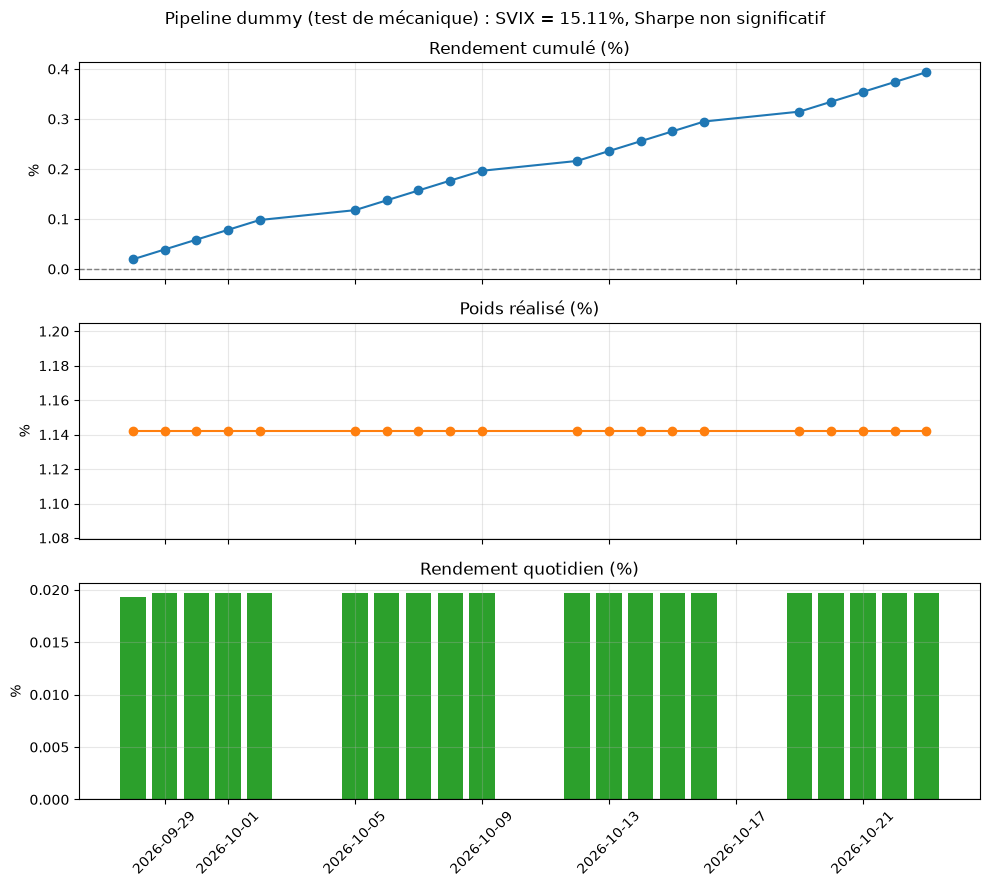

In [21]:
import matplotlib.pyplot as plt

cum_return = (ledger_d["Total_Equity"] / INITIAL_CAPITAL - 1) * 100

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# 1. Rendement cumulé
axes[0].plot(ledger_d.index, cum_return, marker="o", color="tab:blue")
axes[0].axhline(0, ls="--", color="gray", lw=1)
axes[0].set_title("Rendement cumulé (%)")
axes[0].set_ylabel("%")
axes[0].grid(alpha=0.3)

# 2. Poids réalisé
axes[1].plot(ledger_d.index, ledger_d["Position_Weight"] * 100, marker="o", color="tab:orange")
axes[1].set_title("Poids réalisé (%)")
axes[1].set_ylabel("%")
axes[1].grid(alpha=0.3)

# 3. Rendements quotidiens
axes[2].bar(ledger_d.index, ledger_d["Daily_Return"] * 100, color="tab:green", width=0.8)
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("Rendement quotidien (%)")
axes[2].set_ylabel("%")
axes[2].grid(alpha=0.3)

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

sharpe = metrics_d["Sharpe"]
fig.suptitle(
    f"Pipeline dummy (test de mécanique) : SVIX = {svix_d:.2%}, Sharpe non significatif",
    fontsize=12,
)
plt.tight_layout()
plt.show()

In [20]:
rf_avg = np.mean([s.risk_free_rate for s in signals_d])
ret = ledger_d["Daily_Return"]
ex = ret - rf_avg / ANN_FACTOR

print("rf moyen :", rf_avg)
print("Rendements quotidiens :")
print(ret.head(3))
print("Moyenne de l'excès :", ex.mean())
print("Écart-type de l'excès :", ex.std())
print("Sharpe recalculé :", ex.mean() / ex.std() * np.sqrt(ANN_FACTOR))
print("Sharpe du simulateur :", metrics_d["Sharpe"])

rf moyen : 0.05000000000000001
Rendements quotidiens :
Date
2026-09-28    0.000193
2026-09-29    0.000197
2026-09-30    0.000197
Name: Daily_Return, dtype: float64
Moyenne de l'excès : -2.0089210538206216e-06
Écart-type de l'excès : 8.715671623469571e-07
Sharpe recalculé : -36.58998921661054
Sharpe du simulateur : -36.58998921661054
